In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display more columns in the output
pd.set_option("display.max_columns", 100)


In [2]:
#  Load the dataset
df = pd.read_csv("Toronto_Island_ferry_Tickets.csv")
df.head()


,_id,Timestamp,Redemption Count,Sales Count
0,1,2025-12-21T22:30:00,14,16
1,2,2025-12-21T22:15:00,1,0
2,3,2025-12-21T22:00:00,2,0
3,4,2025-12-21T21:30:00,11,1
4,5,2025-12-21T21:15:00,10,0


In [3]:
print("Original dataset shape:", df.shape)


Original dataset shape: (261538, 4)


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 261538 entries, 0 to 261537
Data columns (total 4 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   _id               261538 non-null  int64
 1   Timestamp         261538 non-null  str  
 2   Redemption Count  261538 non-null  int64
 3   Sales Count       261538 non-null  int64
dtypes: int64(3), str(1)
memory usage: 8.0 MB


In [5]:
# Remove unnecessary spaces.
df.columns = df.columns.str.strip()

# Convert Timestamp into a proper datetime format.
# Invalid timestamps become NaT (Not a Time).
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce"
)


In [6]:
# Convert ticket counts into numeric values and Invalid values become NaN.
for col in ["Sales Count", "Redemption Count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove records that have invalid timestamps.
df = df.dropna(subset=["Timestamp"])

# Remove duplicate records using the original record ID,
# when that ID is available.
if "_id" in df.columns:
    df = df.drop_duplicates(subset=["_id"])

# Sort records from oldest to newest.
df = df.sort_values("Timestamp")

print("\nDataset after basic cleaning:", df.shape)



Dataset after basic cleaning: (261538, 4)


In [7]:
df = (
    df.groupby("Timestamp", as_index=False)
      [["Sales Count", "Redemption Count"]]
      .sum(min_count=1)
)
df = df.set_index("Timestamp").sort_index()

print("\nDataset after timestamp aggregation:")
df.head()



Dataset after timestamp aggregation:


,Sales Count,Redemption Count
Timestamp,,
2015-05-01 13:30:00,1,0
2015-05-01 15:15:00,2,0
2015-05-01 15:45:00,1,0
2015-05-01 16:00:00,0,1
2015-05-04 16:00:00,2,0


In [8]:
# Create a continuous 15-minute timeline.

# min_count=1 ensures a completely missing interval stays NaN
# rather than being incorrectly converted to zero.
df = df.resample("15min").sum(min_count=1)

# Identify intervals that contained an original observation.
# This flag is created BEFORE filling missing intervals.
df["Observed_Interval"] = (
    df["Sales Count"].notna()
    | df["Redemption Count"].notna()
).astype(int)

# Missing_Interval = 1 means no original observation existed.
df["Missing_Interval"] = (
    1 - df["Observed_Interval"]
)

print("\nDataset after 15-minute resampling:")
print(df.head(10))

print("\nTotal 15-minute intervals:", len(df))
print("Originally observed intervals:",
      df["Observed_Interval"].sum())
print("Missing intervals:",
      df["Missing_Interval"].sum())



Dataset after 15-minute resampling:
                     Sales Count  Redemption Count  Observed_Interval  \
Timestamp                                                               
2015-05-01 13:30:00          1.0               0.0                  1   
2015-05-01 13:45:00          NaN               NaN                  0   
2015-05-01 14:00:00          NaN               NaN                  0   
2015-05-01 14:15:00          NaN               NaN                  0   
2015-05-01 14:30:00          NaN               NaN                  0   
2015-05-01 14:45:00          NaN               NaN                  0   
2015-05-01 15:00:00          NaN               NaN                  0   
2015-05-01 15:15:00          2.0               0.0                  1   
2015-05-01 15:30:00          NaN               NaN                  0   
2015-05-01 15:45:00          1.0               0.0                  1   

                     Missing_Interval  
Timestamp                              
2015-0

In [9]:
# Handle missing values
# A missing timestamp does not always mean zero ticket sales.The following method interpolates only short gaps of up to two consecutive 15-minute intervals (30 minutes).
#
# Longer gaps remain NaN because interpolation across long & periods can create misleading ticket demand values.

target_columns = ["Sales Count", "Redemption Count"]

df[target_columns] = df[target_columns].interpolate(
    method="time",
    limit=2,
    limit_area="inside"
)

print("\nMissing values after short-gap interpolation:")
print(df[target_columns].isna().sum())



Missing values after short-gap interpolation:
Sales Count         74516
Redemption Count    74516
dtype: int64


In [10]:
# Lag features contain previous observations. Because the data is sampled every 15 minutes:

# Lag 1 = 15 minutes ago
# Lag 2 = 30 minutes ago
# Lag 4 = 1 hour ago
# Lag 8 = 2 hours ago
# Lag 96 = 24 hours ago

for col in target_columns:

    df[f"{col.replace(' ', '_')}_Lag_1"] = df[col].shift(1)

    df[f"{col.replace(' ', '_')}_Lag_2"] = df[col].shift(2)

    df[f"{col.replace(' ', '_')}_Lag_4"] = df[col].shift(4)

    df[f"{col.replace(' ', '_')}_Lag_8"] = df[col].shift(8)

    df[f"{col.replace(' ', '_')}_Lag_96"] = df[col].shift(96)


In [11]:
# Rolling statistics
# Rolling features summarize recent ticket demand.
# Window 4  = previous 1 hour
# Window 8  = previous 2 hours
# Window 96 = previous 24 hours

for col in target_columns:

    feature_name = col.replace(" ", "_")

    for window in [4, 8, 96]:

        previous_values = df[col].shift(1).rolling(
            window=window,
            min_periods=window
        )

        # Average demand during the previous window
        df[f"{feature_name}_RollingMean_{window}"] = (
            previous_values.mean()
        )

        # Variation in demand during the previous window
        df[f"{feature_name}_RollingStd_{window}"] = (
            previous_values.std()
        )

        # Highest demand during the previous window
        df[f"{feature_name}_RollingMax_{window}"] = (
            previous_values.max()
        )



In [12]:
# when use temporal features

df["Hour"] = df.index.hour

df["Minute"] = df.index.minute

# Monday = 0, Tuesday = 1, Wednesday = 2, Thursday = 3, Friday = 4, Saturday = 5, Sunday = 6
df["DayOfWeek"] = df.index.dayofweek

df["Day"] = df.index.day

df["Month"] = df.index.month

df["Year"] = df.index.year

df["Quarter"] = df.index.quarter

# Weekend indicator: 1 = Saturday or Sunday & 0 = Monday to Friday
df["IsWeekend"] = (
    df.index.dayofweek >= 5
).astype(int)

# Optional cyclic time features.
df["Hour_Sin"] = np.sin(
    2 * np.pi * df["Hour"] / 24
)

df["Hour_Cos"] = np.cos(
    2 * np.pi * df["Hour"] / 24
)

df["DayOfWeek_Sin"] = np.sin(
    2 * np.pi * df["DayOfWeek"] / 7
)

df["DayOfWeek_Cos"] = np.cos(
    2 * np.pi * df["DayOfWeek"] / 7
)


In [13]:
df.shape


(373189, 44)

In [14]:

## next-15-minute prediction targets
# ------------------------------------------------------------

# shift(-1) moves the NEXT interval's ticket count
# into the current row.
# Features at 10:00 -> predict Sales Count at 10:15.

df["Sales_Count_Next_15min"] = (
    df["Sales Count"].shift(-1)
)

df["Redemption_Count_Next_15min"] = (
    df["Redemption Count"].shift(-1)
)

# Do not train on rows whose next-interval target is missing.
# The original timeline and missing-interval flags are preserved.
df["Target_Interval_Observed"] = (
    df["Observed_Interval"].shift(-1)
)

# A valid target must exist and must come from an originally
# observed next interval. Interpolated targets are excluded.
df["Target_Valid"] = (
    df["Target_Interval_Observed"].eq(1)
    & df["Sales_Count_Next_15min"].notna()
    & df["Redemption_Count_Next_15min"].notna()
).astype(int)


In [15]:
## Replace infinite values with NaN

df = df.replace([np.inf, -np.inf], np.nan)
df.head()


,Sales Count,Redemption Count,Observed_Interval,Missing_Interval,Sales_Count_Lag_1,Sales_Count_Lag_2,Sales_Count_Lag_4,Sales_Count_Lag_8,Sales_Count_Lag_96,Redemption_Count_Lag_1,Redemption_Count_Lag_2,Redemption_Count_Lag_4,Redemption_Count_Lag_8,Redemption_Count_Lag_96,Sales_Count_RollingMean_4,Sales_Count_RollingStd_4,Sales_Count_RollingMax_4,Sales_Count_RollingMean_8,Sales_Count_RollingStd_8,Sales_Count_RollingMax_8,Sales_Count_RollingMean_96,Sales_Count_RollingStd_96,Sales_Count_RollingMax_96,Redemption_Count_RollingMean_4,Redemption_Count_RollingStd_4,Redemption_Count_RollingMax_4,Redemption_Count_RollingMean_8,Redemption_Count_RollingStd_8,Redemption_Count_RollingMax_8,Redemption_Count_RollingMean_96,Redemption_Count_RollingStd_96,Redemption_Count_RollingMax_96,Hour,Minute,DayOfWeek,Day,Month,Year,Quarter,IsWeekend,Hour_Sin,Hour_Cos,DayOfWeek_Sin,DayOfWeek_Cos,Sales_Count_Next_15min,Redemption_Count_Next_15min,Target_Interval_Observed,Target_Valid
Timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2015-05-01 13:30:00,1.000000,0.0,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13,30,4,1,5,2015,2,0,-0.258819,-0.965926,-0.433884,-0.900969,1.142857,0.0,0.0,0
2015-05-01 13:45:00,1.142857,0.0,0,1,1.000000,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13,45,4,1,5,2015,2,0,-0.258819,-0.965926,-0.433884,-0.900969,1.285714,0.0,0.0,0
2015-05-01 14:00:00,1.285714,0.0,0,1,1.142857,1.000000,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14,0,4,1,5,2015,2,0,-0.500000,-0.866025,-0.433884,-0.900969,NaN,NaN,0.0,0
2015-05-01 14:15:00,NaN,NaN,0,1,1.285714,1.142857,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14,15,4,1,5,2015,2,0,-0.500000,-0.866025,-0.433884,-0.900969,NaN,NaN,0.0,0
2015-05-01 14:30:00,NaN,NaN,0,1,NaN,1.285714,1.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14,30,4,1,5,2015,2,0,-0.500000,-0.866025,-0.433884,-0.900969,NaN,NaN,0.0,0


In [16]:
# Inspect the processed dataset

print("\nProcessed dataset shape:", df.shape)

print("\nFirst five processed records:")
print(df.head())

print("\nAll processed columns:")
print(df.columns.tolist())

print("\nMissing values in the main columns:")
print(
    df[
        [
            "Sales Count",
            "Redemption Count",
            "Sales_Count_Next_15min",
            "Redemption_Count_Next_15min",
        ]
    ].isna().sum()
)

print("\nValid next-interval targets:")
print(df["Target_Valid"].value_counts())




Processed dataset shape: (373189, 48)

First five processed records:
                     Sales Count  Redemption Count  Observed_Interval  \
Timestamp                                                               
2015-05-01 13:30:00     1.000000               0.0                  1   
2015-05-01 13:45:00     1.142857               0.0                  0   
2015-05-01 14:00:00     1.285714               0.0                  0   
2015-05-01 14:15:00          NaN               NaN                  0   
2015-05-01 14:30:00          NaN               NaN                  0   

                     Missing_Interval  Sales_Count_Lag_1  Sales_Count_Lag_2  \
Timestamp                                                                     
2015-05-01 13:30:00                 0                NaN                NaN   
2015-05-01 13:45:00                 1           1.000000                NaN   
2015-05-01 14:00:00                 1           1.142857           1.000000   
2015-05-01 14:15:00    

In [17]:
#Save the complete processed dataset

output_file = "Toronto_Ferry_Forecasting_Features.csv"

df.to_csv(output_file, index_label="Timestamp")

print("\nProcessed dataset saved successfully:")
print(output_file)



Processed dataset saved successfully:
Toronto_Ferry_Forecasting_Features.csv


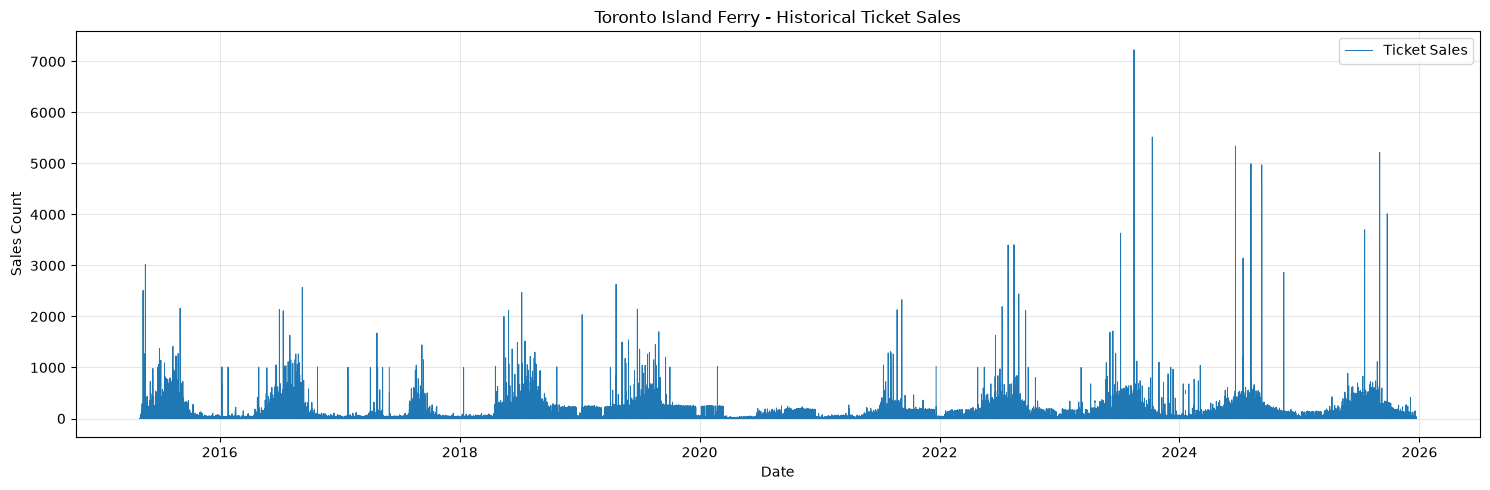

In [18]:
# Plot historical ticket sales
# Plot a sample of the time series. For very large datasets, plotting every point can be slow.

plt.figure(figsize=(15, 5))

plt.plot(
    df.index,
    df["Sales Count"],
    linewidth=0.7,
    label="Ticket Sales"
)

plt.title("Toronto Island Ferry - Historical Ticket Sales")

plt.xlabel("Date")

plt.ylabel("Sales Count")

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()


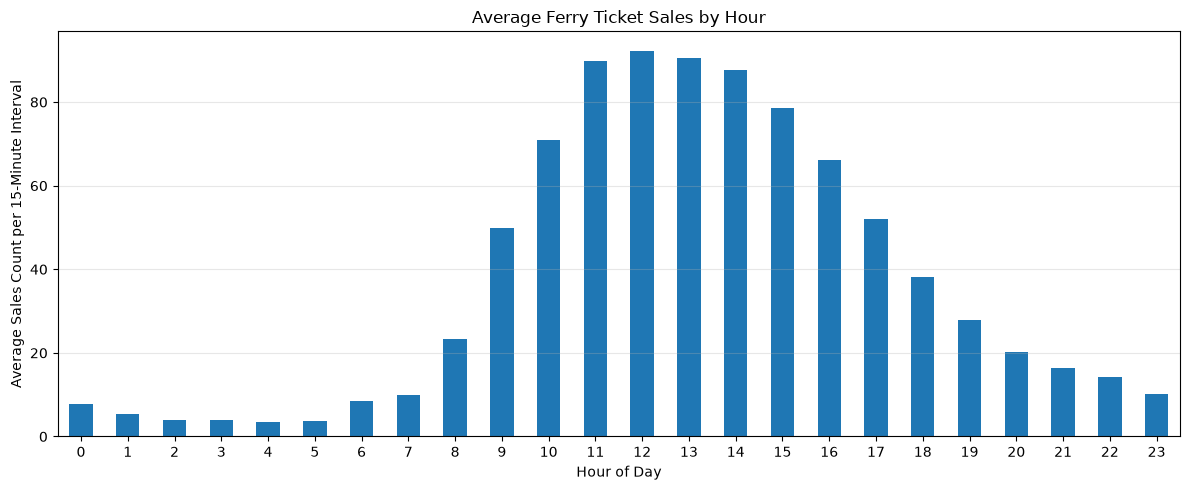


Average demand by hour:
Hour
12    92.304667
13    90.621193
11    89.708547
14    87.722267
15    78.486823
10    70.879055
16    66.215270
17    52.118783
9     49.848156
18    38.140690
19    27.878506
8     23.220970
20    20.248754
21    16.497567
22    14.292603
23    10.150982
7      9.986501
6      8.388217
0      7.721101
1      5.342361
2      4.011950
3      3.843118
5      3.605633
4      3.368237
Name: Sales Count, dtype: float64


In [19]:
# Analyze average demand by hour
# Calculate average sales for each hour of the day, This helps identify potentially busy operating hours.

hourly_demand = (
    df.groupby("Hour")["Sales Count"]
      .mean()
)

plt.figure(figsize=(12, 5))

hourly_demand.plot(kind="bar")

plt.title("Average Ferry Ticket Sales by Hour")

plt.xlabel("Hour of Day")

plt.ylabel("Average Sales Count per 15-Minute Interval")

plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

print("\nAverage demand by hour:")
print(hourly_demand.sort_values(ascending=False))


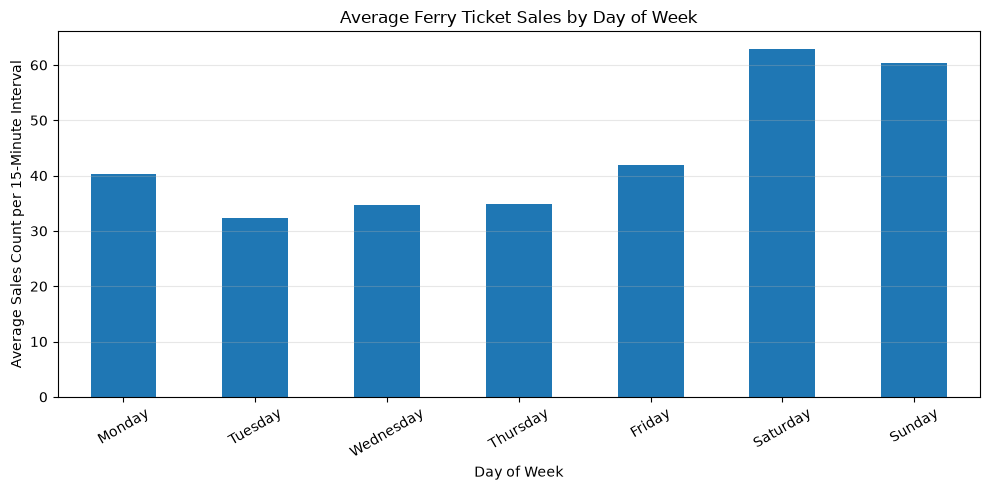


Average demand by weekday:
DayOfWeek
Saturday     62.937879
Sunday       60.406252
Friday       41.898868
Monday       40.237050
Thursday     34.939609
Wednesday    34.601722
Tuesday      32.262667
Name: Sales Count, dtype: float64


In [20]:
# Analyze weekday patterns

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
    df.groupby("DayOfWeek")["Sales Count"]
      .mean()
)

weekday_demand.index = weekday_demand.index.map(
    lambda day: weekday_names[day]
)

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")
plt.title("Average Ferry Ticket Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales Count per 15-Minute Interval")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nAverage demand by weekday:")
print(weekday_demand.sort_values(ascending=False))



In [21]:
##Prepare a chronological train/test split
#
#
# Use only rows with valid next-interval targets, Do not randomly shuffle time-series data.

# The earliest 80% of valid observations are used for training; & the latest 20% are reserved for testing.

model_data = df.loc[
    df["Target_Valid"].eq(1)
].copy()

# Exclude current target counts from this list because lag and rolling features represent the past, while calendar features
# describe the prediction time.

feature_columns = [
    col for col in model_data.columns
    if (
        "_Lag_" in col
        or "_RollingMean_" in col
        or "_RollingStd_" in col
        or "_RollingMax_" in col
        or col in [
            "Hour", "Minute", "DayOfWeek", "Day",
            "Month", "Year", "Quarter", "IsWeekend",
            "Hour_Sin", "Hour_Cos",
            "DayOfWeek_Sin", "DayOfWeek_Cos",
            "Observed_Interval", "Missing_Interval"
        ]
    )
]

# Remove rows with unavailable features, such as the first 24 hours where a 96-interval lag is not yet available.


model_data = model_data.dropna(
    subset=feature_columns
    + [
        "Sales_Count_Next_15min",
        "Redemption_Count_Next_15min"
    ]
)

split_index = int(len(model_data) * 0.80)

train_data = model_data.iloc[:split_index]

test_data = model_data.iloc[split_index:]

X_train = train_data[feature_columns]

X_test = test_data[feature_columns]

y_train_sales = train_data["Sales_Count_Next_15min"]

y_test_sales = test_data["Sales_Count_Next_15min"]

y_train_redemptions = train_data[
    "Redemption_Count_Next_15min"
]

y_test_redemptions = test_data[
    "Redemption_Count_Next_15min"
]



In [22]:

print("\nTraining rows:", len(X_train))

print("Testing rows:", len(X_test))

print("Number of input features:", len(feature_columns))

print("\nTraining period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting period:")
print(test_data.index.min(), "to", test_data.index.max())

print("\nPreprocessing and feature engineering completed!")





Training rows: 5168
Testing rows: 1293
Number of input features: 42

Training period:
2016-07-24 03:15:00 to 2025-06-07 11:30:00

Testing period:
2025-06-07 11:45:00 to 2025-08-31 03:30:00

Preprocessing and feature engineering completed!
